In [1]:
import pandas as pd
import numpy as np
from optbinning import BinningProcess

df = pd.read_parquet("../data/processed/accepted_clean.parquet")

# Same out-of-time split as in notebook 01
train = df[(df["issue_d"] >= "2012-01-01") & (df["issue_d"] < "2015-01-01")].copy()
test  = df[(df["issue_d"] >= "2015-01-01") & (df["issue_d"] < "2016-01-01")].copy()

# Excluded: date, target, constant column (term), and installment (nearly duplicates loan_amnt)
drop_cols = ["issue_d", "target", "term", "installment"]
features = [c for c in df.columns if c not in drop_cols]
cat_vars = ["home_ownership", "verification_status", "purpose",
            "addr_state", "application_type"]

X_train, y_train = train[features], train["target"]
X_test,  y_test  = test[features],  test["target"]
print(len(features), "features,", X_train.shape, X_test.shape)

21 features, (306462, 21) (283026, 21)


In [2]:
# Optimal binning + WoE/IV; only features with 0.02 <= IV <= 0.5 are selected
# (IV < 0.02 = too weak, IV > 0.5 = suspiciously strong, possible leakage)
binning_process = BinningProcess(
    variable_names=features,
    categorical_variables=cat_vars,
    min_prebin_size=0.02,
    selection_criteria={"iv": {"min": 0.02, "max": 0.5}},
)
binning_process.fit(X_train, y_train)

summary = binning_process.summary().sort_values("iv", ascending=False)
summary

,name,dtype,status,selected,n_bins,iv,js,gini,quality_score
19,fico_avg,numerical,OPTIMAL,True,17,0.136164,0.016626,0.193243,0.098995
2,annual_inc,numerical,OPTIMAL,True,16,0.089067,0.01105,0.169742,0.066537
6,dti,numerical,OPTIMAL,True,15,0.049065,0.006108,0.126019,0.03356
20,loan_to_income,numerical,OPTIMAL,True,11,0.045651,0.005681,0.117135,0.03104
15,mort_acc,numerical,OPTIMAL,True,7,0.044556,0.005553,0.114925,0.121979
1,home_ownership,categorical,OPTIMAL,True,3,0.039006,0.004867,0.101918,0.140632
8,inq_last_6mths,numerical,OPTIMAL,True,5,0.028437,0.003546,0.088897,0.08332
12,revol_util,numerical,OPTIMAL,True,14,0.021971,0.002737,0.079501,0.000115
4,purpose,categorical,OPTIMAL,True,6,0.021643,0.002695,0.072352,0.033439
18,credit_history_yrs,numerical,OPTIMAL,True,11,0.021345,0.002661,0.08103,0.007802


,Bin,Count,Count (%),Non-event,Event,Event rate,WoE,IV,JS
0,"(-inf, 664.50)",27011,0.088138,22003,5008,0.185406,-0.399181,1.620760e-02,2.012606e-03
1,"[664.50, 669.50)",27151,0.088595,22405,4746,0.174800,-0.327341,1.068319e-02,1.329469e-03
2,"[669.50, 674.50)",27529,0.089828,22836,4693,0.170475,-0.297057,8.825444e-03,1.099142e-03
3,"[674.50, 679.50)",24798,0.080917,20903,3895,0.157069,-0.199124,3.449443e-03,4.304694e-04
4,"[679.50, 684.50)",24662,0.080473,20850,3812,0.154570,-0.180123,2.787927e-03,3.480205e-04
5,"[684.50, 689.50)",22025,0.071869,18830,3195,0.145062,-0.105459,8.307169e-04,1.037915e-04
6,"[689.50, 694.50)",21216,0.069229,18411,2805,0.132212,0.002222,3.414895e-07,4.268618e-08
7,"[694.50, 699.50)",19146,0.062474,16686,2460,0.128486,0.035086,7.591996e-05,9.489509e-06
8,"[699.50, 704.50)",17053,0.055645,15052,2001,0.117340,0.138541,1.014731e-03,1.267401e-04
9,"[704.50, 709.50)",15230,0.049696,13554,1676,0.110046,0.210949,2.045299e-03,2.551894e-04


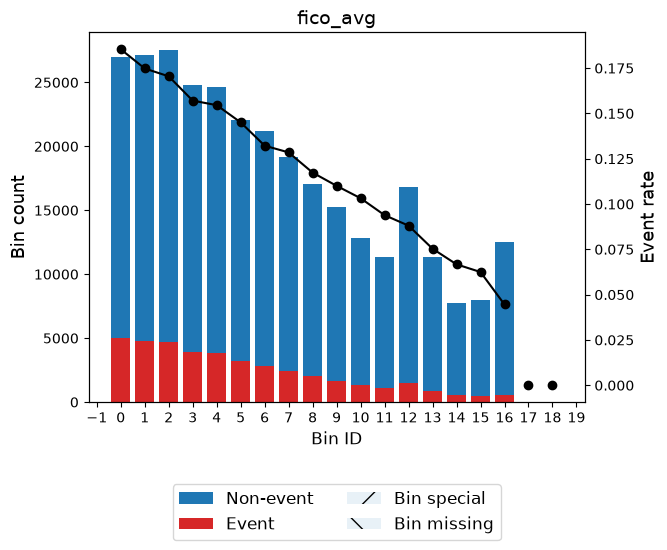

In [3]:
# Inspect the bins of one variable: the event rate should move in a sensible direction
var = "fico_avg"
bv = binning_process.get_binned_variable(var)
display(bv.binning_table.build())
bv.binning_table.plot(metric="event_rate")

In [4]:
# Transform to WoE using bins learned on the training set only (no leakage into test)
X_train_woe = binning_process.transform(X_train, metric="woe")
X_test_woe  = binning_process.transform(X_test,  metric="woe")

X_train_woe["target"] = y_train.values
X_test_woe["target"]  = y_test.values

X_train_woe.to_parquet("../data/processed/train_woe.parquet")
X_test_woe.to_parquet("../data/processed/test_woe.parquet")
print(X_train_woe.shape, X_test_woe.shape)

(306462, 11) (283026, 11)
